In [1]:
from db_queries import get_ids, get_population, get_covariate_estimates, get_best_model_versions, get_outputs
from get_draws.api import get_draws
import pandas as pd, numpy as np, os
import matplotlib.pyplot as plt

# Back-of-the-envelope: CVD and ambient PM pollution
How many additional CVD deaths (or some other outcome measure?) will there be with an increase in air pollution levels in Washington State?

- A = CVD deaths (or another outcome metric?)  
- B = Effect of air pollution on CVD outcomes (separate RRs for IHD and stroke? Other forms of CVD?) 
- C = Change in air pollution levels (what units? From FHS estimate?)



``A * B * C = X``, where X is the additional deaths with each C increase in air pollution levels 

Related links: 
- [Ambient PM pollution Methods Appendix 2021](https://www.healthdata.org/gbd/methods-appendices-2021/ambient-particulate-matter-pollution)
- [Syl's B-O-E calculation notebook from CVD sim](https://github.com/ihmeuw/vivarium_research_nih_us_cvd/blob/main/data_testing_exploration/Back_of_envelope.ipynb)
- [SharePoint notes](https://uwnetid.sharepoint.com/sites/ihme_simulation_science_team/_layouts/15/doc.aspx?sourcedoc={89f5b873-f051-4e2f-9032-9d5a42c59bda}&action=edit)
- [Abie's slides on B-O-E calculations](https://www.dropbox.com/scl/fi/04fy98nlj158wlpw44peb/vivarium_back_of_envelop_method.pptx?rlkey=v8n9m0qi2ts2k3k0c836dhp7z&e=1&dl=0)
- [CVD Concept Model docs](https://vivarium-research.readthedocs.io/en/latest/models/concept_models/vivarium_us_cvd/concept_model.html)

# First calculation: How many CVD deaths are currently attributable to ambient air pollution? 
``CVD deaths due to air pollution = total CVD deaths * air pollution PAF``

First, I am going to focus on the 50-69 years age group and males, but this population is quite small and this calculation would be more interesting if I include all age groups and sexes.

In [16]:
# CVD deaths (count) in Washington State in 2021 for 50-69 year old males
cvd_deaths = get_draws(location_id=570, # Washington State
         gbd_id_type='cause_id',
         gbd_id=[491,493,495,496,497], # 491 is overall CVD cause
         source='codcorrect',
         year_id=2021,
         release_id=9,
         measure_id=1,
         metric_id=1,
         age_group_id=16, # 55-59 years
         sex_id=1 # Male
         )
cvd_deaths

#  cause_id=493 is Ischemic Heart Disease
#  cause_id=495 is Ischemic Stroke
#  cause_id=496 is Intracerebral Hemorrhage
#  cause_id=497 is Subarachnoid Hemorrhage

/ihme/homes/pletale/.conda/envs/vivarium_gates_mncnh/lib/python3.11/site-packages/get_draws/api.py:194: UserWarning: No version_id was specified, so get_draws will automatically determine a best version ID to use from the given parameters. If you want to retrieve a specific version please pass a version_id directly.
  warnings.warn(


,location_id,year_id,sex_id,age_group_id,cause_id,measure_id,draw_0,draw_1,draw_2,draw_3,...,draw_492,draw_493,draw_494,draw_495,draw_496,draw_497,draw_498,draw_499,metric_id,version_id
0,570,2021,1,16,491,1,401.091660,325.750091,378.127121,467.891882,...,400.302124,388.992915,412.447987,501.117659,544.841121,452.085804,439.740099,504.506578,1,393
1,570,2021,1,16,493,1,240.676127,198.657109,229.106782,279.349567,...,256.825790,237.049814,237.526489,306.188659,336.293844,281.415206,270.309663,293.273622,1,393
2,570,2021,1,16,495,1,10.506318,8.320003,8.587792,11.780237,...,8.739933,9.785227,10.508717,11.750438,11.946890,12.188297,10.416054,13.132288,1,393
3,570,2021,1,16,496,1,31.602034,24.075285,30.445998,33.767286,...,28.048816,30.896499,32.513273,36.325328,38.803479,33.435147,31.319221,38.508570,1,393
4,570,2021,1,16,497,1,15.290452,10.517663,13.055994,15.514825,...,10.573708,10.369749,14.095795,15.696969,15.370398,15.104272,12.412169,18.942856,1,393


In [ ]:
%%time

# Ambient air pollution PAF
air_pm_paf = get_draws(location_id=570, # Washington State
         gbd_id_type='rei_id',
         gbd_id=86, # Ambient particulate matter pollution
         source='burdenator', 
         year_id=2021,
         release_id=9,
         measure_id=4,
         metric_id=2,
         age_group_id=16, # 55-59 years 
         sex_id=1 # Male 
         )

air_pm_paf
# This call should return the ambient air pollution PAF. It returns rates of YLDs (measure_id = 3) and YLLs (measure_id = 4), but I am 
# filtering to YLLs because I am looking at CVD mortality not morbidity.

# There is no ambient air pollution PAF for CVD as an umbrella cause, so doing each of the sub-causes separately.

/ihme/homes/pletale/.conda/envs/vivarium_gates_mncnh/lib/python3.11/site-packages/get_draws/api.py:194: UserWarning: No version_id was specified, so get_draws will automatically determine a best version ID to use from the given parameters. If you want to retrieve a specific version please pass a version_id directly.
  warnings.warn(


CPU times: user 2.99 s, sys: 2.79 s, total: 5.78 s
Wall time: 4min 7s


,age_group_id,cause_id,location_id,measure_id,metric_id,sex_id,year_id,draw_0,draw_1,draw_2,...,draw_492,draw_493,draw_494,draw_495,draw_496,draw_497,draw_498,draw_499,rei_id,version_id
0,16,294,570,4,2,1,2021,0.011325,0.001098,0.006958,...,0.001314,0.006762,0.002722,0.006899,0.006147,0.013220,0.008144,0.009302,86,295
1,16,295,570,4,2,1,2021,0.000907,0.000178,0.001198,...,0.000356,0.001448,0.000256,0.001841,0.002860,0.003594,0.003365,0.003575,86,295
2,16,322,570,4,2,1,2021,0.016500,0.005385,0.021127,...,0.006437,0.033934,0.003547,0.022911,0.023025,0.047922,0.042559,0.035690,86,295
3,16,409,570,4,2,1,2021,0.015767,0.001555,0.009710,...,0.001746,0.008916,0.003562,0.008686,0.007345,0.016550,0.010099,0.011679,86,295
4,16,410,570,4,2,1,2021,0.008083,0.000892,0.005715,...,0.000670,0.004059,0.001388,0.004028,0.002992,0.009528,0.004168,0.005370,86,295
5,16,426,570,4,2,1,2021,0.036584,0.004190,0.023027,...,0.003070,0.017133,0.006354,0.017203,0.013071,0.041451,0.020879,0.024802,86,295
6,16,491,570,4,2,1,2021,0.031025,0.002990,0.019224,...,0.003685,0.019255,0.007825,0.019310,0.017213,0.035218,0.020531,0.023075,86,295
7,16,493,570,4,2,1,2021,0.044282,0.004293,0.026958,...,0.005072,0.028243,0.012029,0.027922,0.024575,0.049824,0.029465,0.033802,86,295
8,16,494,570,4,2,1,2021,0.032078,0.003051,0.021836,...,0.003844,0.016004,0.006599,0.017177,0.015683,0.031561,0.019520,0.024965,86,295
9,16,495,570,4,2,1,2021,0.032049,0.003078,0.021789,...,0.003802,0.015854,0.006609,0.017125,0.015687,0.031520,0.019516,0.024868,86,295


In [10]:
air_pm_paf = air_pm_paf[air_pm_paf['cause_id'].isin([493, 495, 496, 497])]
air_pm_paf 

,age_group_id,cause_id,location_id,measure_id,metric_id,sex_id,year_id,draw_0,draw_1,draw_2,...,draw_492,draw_493,draw_494,draw_495,draw_496,draw_497,draw_498,draw_499,rei_id,version_id
7,16,493,570,4,2,1,2021,0.044282,0.004293,0.026958,...,0.005072,0.028243,0.012029,0.027922,0.024575,0.049824,0.029465,0.033802,86,295
9,16,495,570,4,2,1,2021,0.032049,0.003078,0.021789,...,0.003802,0.015854,0.006609,0.017125,0.015687,0.031520,0.019516,0.024868,86,295
10,16,496,570,4,2,1,2021,0.032049,0.003078,0.021789,...,0.003802,0.015854,0.006609,0.017125,0.015687,0.031520,0.019516,0.024868,86,295
11,16,497,570,4,2,1,2021,0.032049,0.003078,0.021789,...,0.003802,0.015854,0.006609,0.017125,0.015687,0.031520,0.019516,0.024868,86,295


In [6]:
# Is there a difference between Particulate matter pollution (rei_id=380) and Ambient particulate matter pollution (rei_id=86)?

# What is the difference between the call from source='paf' and source='burdenator'?
# Answer: Because age/sex/location/cause aggregation of attributable burden doesn’t occur until the burdenator and risk aggregation 
# happens between running save_results_risk on the PAF draws and running the burdenator, age/sex/location/cause/rei aggregates are 
# missing from the “paf” source. If you want aggregates, burdenator would be a better option! (https://scicomp-docs.ihme.washington.edu/get_draws/current/sources.html#paf)


In [11]:
air_pm_paf.metric_id.value_counts()
# metric_id = 2 means percentage -- should I divide by 100 to get a proportion instead? 

2    4
Name: metric_id, dtype: int64

In [19]:
# 1. Get total deaths for each sub-cause (e.g., IHD, stroke, etc.)
subcause_deaths = cvd_deaths[cvd_deaths['cause_id'].isin([493, 495, 496, 497])]
draw_cols = [col for col in subcause_deaths.columns if col.startswith('draw_')]

# 2. Sum deaths across sub-causes for each draw
total_subcause_deaths = subcause_deaths[draw_cols].sum()

# 3. Calculate the proportion of deaths for each sub-cause and draw
proportions = subcause_deaths.set_index('cause_id')[draw_cols].div(total_subcause_deaths)

# 4. Get the PAF for each sub-cause and draw
subcause_pafs = air_pm_paf.set_index('cause_id')[draw_cols]

# 5. Calculate weighted PAF for each draw
weighted_paf = (proportions * subcause_pafs).sum()

# 6. Get overall CVD deaths (cause_id=491)
overall_cvd_deaths = cvd_deaths[cvd_deaths['cause_id'] == 491][draw_cols].iloc[0]

# 7. Calculate overall CVD deaths due to air pollution for each draw
cvd_deaths_due_to_air_pm = overall_cvd_deaths * weighted_paf

# 8. Summarize results
mean = cvd_deaths_due_to_air_pm.mean()
lower = cvd_deaths_due_to_air_pm.quantile(0.025)
upper = cvd_deaths_due_to_air_pm.quantile(0.975)
print(f"Mean: {mean:.2f}, 95% CI: ({lower:.2f}, {upper:.2f})")


Mean: 9.97, 95% CI: (1.80, 21.62)


In [ ]:
# TODO: Re-do above calculation to include all age groups and sexes so that I can 
# use this plotting code to visualize the results.


# age_group_map = {
#     2: "0–4", 3: "5–9", 4: "10–14", 5: "15–19", 6: "20–24",
#     7: "25–29", 8: "30–34", 9: "35–39", 10: "40–44",
#     11: "45–49", 12: "50–54", 13: "55–59", 14: "60–64",
#     15: "65–69", 16: "70–74", 17: "75–79", 18: "80–84",
#     19: "85–89", 20: "90–94", 30: "95-99"
# }
# sex_map = {
#     1: "Male",
#     2: "Female"
# }

# s = cvd_deaths_due_to_air_pm.copy()
# s["mean"] = s.loc[:, "draw_0":"draw_999"].mean(axis=1)
# s["lower"] = s.loc[:, "draw_0":"draw_999"].quantile(0.025, axis=1)
# s["upper"] = s.loc[:, "draw_0":"draw_999"].quantile(0.975, axis=1)
# s = s.reset_index()
# s["age_group_name"] = s["age_group_id"].map(age_group_map)
# s = s.dropna(subset=["age_group_name"])

# ordered_ages = [age_group_map[i] for i in sorted(age_group_map) if i in s["age_group_id"].unique()]
# s["age_group_name"] = pd.Categorical(
#     s["age_group_name"], categories=ordered_ages, ordered=True
# )
# s = s.sort_values("age_group_name")


# fig, ax = plt.subplots(figsize=(12, 6))
# for sex in sorted(s["sex_id"].unique()):
#     subset = s[s["sex_id"] == sex]
#     x = subset["age_group_name"]
#     y = subset["mean"]
#     lower = subset["lower"]
#     upper = subset["upper"]

#     label = sex_map.get(sex, f"Sex {sex}")
#     ax.plot(x, y, label=label, marker='o')
#     ax.fill_between(x, lower, upper, alpha=0.3)
# ax.set_xlabel("Age Group")
# ax.set_ylabel("CVD Deaths Attributable to Air Pollution")
# ax.set_title("Air Pollution-Attributable CVD Deaths in WA State in 2021")
# ax.legend(title="Sex")
# plt.xticks(rotation=45)
# plt.tight_layout()
# plt.show()

## Validity Check: Calculate the 2021 PAF using ambient PM pollution SEVs from GBD, and compare to PAFs pulled directly from get_covariate_estimates above
``PAF = (SEV(RRmax - 1)) / (1 + SEV(RRmax -1))``


If these are similar, then I will be more confident in the calculation below using the forecasted SEV to approximate a forecasted PAF, and thus a forecasted number of CVD deaths 
due to air pollution (and I can compare forecasts between Reference Scenario and Safer Scenario).

In [22]:
# Pull age- and sex-specific SEV for ambient PM pollution from GBD
air_pm_sev_2021 = get_covariate_estimates(
        location_id=570, # Washington State 
         covariate_id=2042, # Ambient PM pollution SEV
         release_id=9,
         year_id=2021,
         age_group_id=16, # 55-59 years 
         sex_id=1 # Male 
         )

air_pm_sev_2021

,model_version_id,covariate_id,covariate_name_short,location_id,location_name,year_id,age_group_id,age_group_name,sex_id,sex,mean_value,lower_value,upper_value
0,38360,2042,SEV_air_pm,570,Washington,2021,16,55 to 59,1,Male,0.040251,0.040251,0.040251


In [ ]:
# Pull RRmax for ambient PM pollution from GBD 2021 
# TODO: Confirm that GBD assumes that RRmax does not change over time

air_pm_rr_max = get_draws("rei_id",
                           86,
                           source="rr_max", 
                           release_id=9,
                           )
air_pm_rr_max

,rei_id,cause_id,age_group_id,sex_id,draw_0,draw_1,draw_2,draw_3,draw_4,draw_5,...,draw_491,draw_492,draw_493,draw_494,draw_495,draw_496,draw_497,draw_498,draw_499,model_version_id
0,86,322,2,1,1.217033,1.855508,1.448763,1.677130,1.285256,2.207955,...,1.393274,1.812002,2.016768,1.224273,1.582884,1.755376,1.729378,2.283371,1.743492,470
1,86,322,2,2,1.217033,1.855508,1.448763,1.677130,1.285256,2.207955,...,1.393274,1.812002,2.016768,1.224273,1.582884,1.755376,1.729378,2.283371,1.743492,470
2,86,322,3,1,1.217033,1.855508,1.448763,1.677130,1.285256,2.207955,...,1.393274,1.812002,2.016768,1.224273,1.582884,1.755376,1.729378,2.283371,1.743492,470
3,86,322,3,2,1.217033,1.855508,1.448763,1.677130,1.285256,2.207955,...,1.393274,1.812002,2.016768,1.224273,1.582884,1.755376,1.729378,2.283371,1.743492,470
4,86,322,6,1,1.217033,1.855508,1.448763,1.677130,1.285256,2.207955,...,1.393274,1.812002,2.016768,1.224273,1.582884,1.755376,1.729378,2.283371,1.743492,470
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
259,86,976,235,2,1.313403,1.298557,1.299722,1.166332,1.438199,1.309918,...,1.374693,1.306904,1.196558,1.264183,1.282987,1.203177,1.235923,1.446812,1.388034,470
260,86,1061,2,1,25.040133,34.494004,34.752578,40.109791,43.305912,26.736723,...,31.349456,23.822337,28.134509,41.783789,31.463074,35.551828,28.668641,28.977668,33.649696,470
261,86,1061,2,2,36.422439,27.643929,34.527322,26.073034,33.346949,29.517102,...,47.543348,25.116086,24.539340,32.113029,34.120320,34.222839,22.063963,38.398385,33.215548,470
262,86,1061,3,1,17.771673,20.536461,19.298239,15.757210,18.240727,20.500171,...,18.070869,17.760281,18.590346,16.200678,20.025494,17.115726,18.772682,17.697102,21.132297,470


In [38]:
# Filter to CVD sub-causes and same age group and sex as above 
air_pm_rr_max = air_pm_rr_max[
            (air_pm_rr_max['cause_id'].isin([493, 495, 496, 497])) &
            (air_pm_rr_max['age_group_id'] == 16) &
            (air_pm_rr_max['sex_id'] == 1)
        ]
air_pm_rr_max

,rei_id,cause_id,age_group_id,sex_id,draw_0,draw_1,draw_2,draw_3,draw_4,draw_5,...,draw_491,draw_492,draw_493,draw_494,draw_495,draw_496,draw_497,draw_498,draw_499,model_version_id
92,86,493,16,1,1.918678,1.800007,1.757989,2.032657,1.799113,1.819618,...,1.741957,1.823599,2.039603,2.123668,1.906066,2.015574,1.977034,1.957229,1.879274,470
122,86,495,16,1,1.894618,1.772149,1.859285,1.719785,1.852701,1.701156,...,1.788171,1.765323,1.687746,1.784366,1.705839,1.813704,1.788861,1.800374,1.868763,470
152,86,496,16,1,1.894618,1.772149,1.859285,1.719785,1.852701,1.701156,...,1.788171,1.765323,1.687746,1.784366,1.705839,1.813704,1.788861,1.800374,1.868763,470
182,86,497,16,1,1.894618,1.772149,1.859285,1.719785,1.852701,1.701156,...,1.788171,1.765323,1.687746,1.784366,1.705839,1.813704,1.788861,1.800374,1.868763,470


In [43]:
# Calculate PAF for each sub-cause and draw
air_pm_paf_approx = (air_pm_sev_2021 * (air_pm_rr_max - 1)) / (1 + air_pm_sev_2021 * (air_pm_rr_max - 1))
air_pm_paf_approx


,age_group_id,age_group_name,cause_id,covariate_id,covariate_name_short,draw_0,draw_1,draw_10,draw_100,draw_101,...,location_id,location_name,lower_value,mean_value,model_version_id,rei_id,sex,sex_id,upper_value,year_id
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
92,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
122,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
152,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
182,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
# sev = sev_row[[col for col in air_pm_sev_2021.columns if col.startswith('draw_')]].iloc[0]

# # Get RRmax for each cause (as a DataFrame)
# rrmax = air_pm_rr_max.set_index('cause_id')[[col for col in air_pm_rr_max.columns if col.startswith('draw_')]]

# # Broadcast SEV to match RRmax shape
# sev_matrix = pd.DataFrame([sev.values] * rrmax.shape[0], columns=sev.index, index=rrmax.index)

# # Calculate PAF for each sub-cause and draw
# air_pm_paf_approx = (sev_matrix * (rrmax - 1)) / (1 + sev_matrix * (rrmax - 1))
# air_pm_paf_approx

0.040251*(1.918678-1) / (1 + 0.040251*(1.918678-1))
# Compared to the PAF from GBD, this is a bit lower (0.040251 vs 0.036), but maybe close enough?

# TODO: Fix this calculation to use the dataframes above instead of hard-coded values and 
# use draws for uncertainty to get a better idea how close these PAFs really are.

0.035659115800059885

## Pull forecasted data for 2030

1. ``CVD deaths due to air pollution in 2030 in reference scenario = total CVD deaths in 2030 * reference PAF``
2. ``CVD deaths due to air pollution in 2030 in Safer Environment scenario = total CVD deaths in 2030 * safer environment PAF``
3. ``(2) - (1) = CVD deaths that could be avoided with less polluted air``

Docs for how to pull FHS results using ``get_outputs()``: https://scicomp-docs.ihme.washington.edu/db_queries/current/get_outputs/forecasted.html

https://hub.ihme.washington.edu/pages/viewpage.action?pageId=349078118&spaceKey=FHSENG&title=FHS%2BResults%2Bvia%2BGet_Outputs

FHS Foresight Viz Results Tool: https://vizhub.healthdata.org/gbd-foresight/

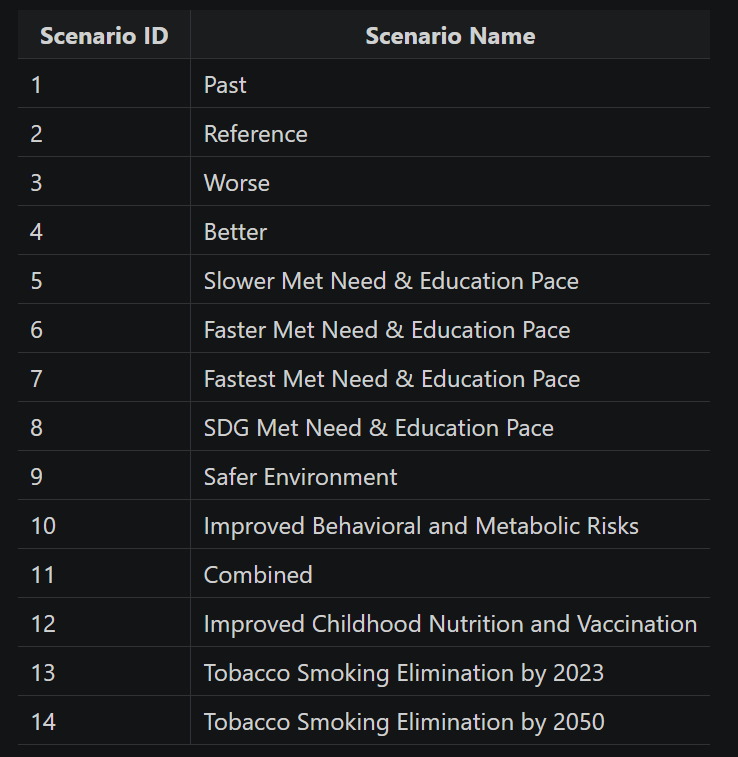

In [55]:
# Let's start with the forecasted reference scenario for 2030
air_pm_sev_ref = get_outputs(
    "rei",
    rei_id=86,
    location_id=570,
    release_id=6,
    measure_id=29,
    metric_id=3,
    year_id=2030,
    forecasted=True,
    scenario_id=2,
    sex_id=1,  
    age_group_id=16,  # 55-59 years
)
air_pm_sev_ref

/ihme/homes/pletale/.conda/envs/vivarium_gates_mncnh/lib/python3.11/site-packages/db_queries/legacy/get_outputs_helpers/formatting.py:263: UserWarning: When looking for rei_names, we are missing values given rei_set_id: 21. Filling with latest names from rei db table. WARNING: Be very careful if sharing these results with collaborators!!
  warnings.warn(


,age_group_id,location_id,measure_id,metric_id,rei_id,scenario_id,sex_id,year_id,age_group_name,expected,...,location_type,measure,measure_name,metric_name,rei,rei_name,sex,val,upper,lower
0,16,570,29,3,86,2,1,2030,55 to 59,False,...,admin1,sev,Summary exposure value,Rate,air_pm,Ambient particulate matter pollution,Male,0.037311,0.069318,0.012629


In [56]:
air_pm_rr_max

,rei_id,cause_id,age_group_id,sex_id,draw_0,draw_1,draw_2,draw_3,draw_4,draw_5,...,draw_491,draw_492,draw_493,draw_494,draw_495,draw_496,draw_497,draw_498,draw_499,model_version_id
92,86,493,16,1,1.918678,1.800007,1.757989,2.032657,1.799113,1.819618,...,1.741957,1.823599,2.039603,2.123668,1.906066,2.015574,1.977034,1.957229,1.879274,470
122,86,495,16,1,1.894618,1.772149,1.859285,1.719785,1.852701,1.701156,...,1.788171,1.765323,1.687746,1.784366,1.705839,1.813704,1.788861,1.800374,1.868763,470
152,86,496,16,1,1.894618,1.772149,1.859285,1.719785,1.852701,1.701156,...,1.788171,1.765323,1.687746,1.784366,1.705839,1.813704,1.788861,1.800374,1.868763,470
182,86,497,16,1,1.894618,1.772149,1.859285,1.719785,1.852701,1.701156,...,1.788171,1.765323,1.687746,1.784366,1.705839,1.813704,1.788861,1.800374,1.868763,470


In [58]:
air_pm_paf_ref = 0.0373*(1.919-1) / (1 + 0.0373*(1.919-1))
air_pm_paf_ref 

0.03314261426828185

In [53]:
total_cvd_deaths_ref = get_outputs(
    "cause",
    cause_id=491,
    location_id=570,
    release_id=6,
    measure_id=1,
    metric_id=1,
    year_id=2030,
    forecasted=True,
    scenario_id=2,
    sex_id=1,  
    age_group_id=16,  # 55-59 years
)
total_cvd_deaths_ref  # Can specify sex and age groups 

,age_group_id,cause_id,location_id,measure_id,metric_id,scenario_id,sex_id,year_id,acause,age_group_name,...,expected,location_name,location_type,measure,measure_name,metric_name,sex,val,upper,lower
0,16,491,570,1,1,2,1,2030,cvd,55 to 59,...,False,Washington,admin1,death,Deaths,Number,Male,361.772127,477.702179,263.279011


In [60]:
361.772 * 0.03314

11.98912408

In [61]:
sev_safer = get_outputs(
    "rei",
    rei_id=86,
    location_id=570,
    release_id=6,
    measure_id=29,
    metric_id=3,
    year_id=2030,
    forecasted=True,
    scenario_id=9,
    sex_id=1,  
    age_group_id=16,  # 55-59 years
)
sev_safer

# At least currently we only have the Reference Scenario and the Safer Environment Scenario

/ihme/homes/pletale/.conda/envs/vivarium_gates_mncnh/lib/python3.11/site-packages/db_queries/legacy/get_outputs_helpers/formatting.py:263: UserWarning: When looking for rei_names, we are missing values given rei_set_id: 21. Filling with latest names from rei db table. WARNING: Be very careful if sharing these results with collaborators!!
  warnings.warn(


,age_group_id,location_id,measure_id,metric_id,rei_id,scenario_id,sex_id,year_id,age_group_name,expected,...,location_type,measure,measure_name,metric_name,rei,rei_name,sex,val,upper,lower
0,16,570,29,3,86,9,1,2030,55 to 59,False,...,admin1,sev,Summary exposure value,Rate,air_pm,Ambient particulate matter pollution,Male,0.028203,0.051182,0.009406


In [63]:
air_pm_paf_safer = 0.0282*(1.919-1) / (1 + 0.0282*(1.919-1))
air_pm_paf_safer

0.02526113741498084

In [62]:
deaths_safer = get_outputs(
    "cause",
    cause_id=491,
    location_id=570,
    release_id=6,
    measure_id=1,
    metric_id=1,
    year_id=2030,
    forecasted=True,
    scenario_id=9,    
    sex_id=1,  
    age_group_id=16,  # 55-59 years
)
deaths_safer

,age_group_id,cause_id,location_id,measure_id,metric_id,scenario_id,sex_id,year_id,acause,age_group_name,...,expected,location_name,location_type,measure,measure_name,metric_name,sex,val,upper,lower
0,16,491,570,1,1,9,1,2030,cvd,55 to 59,...,False,Washington,admin1,death,Deaths,Number,Male,360.511015,476.117065,262.355047


In [64]:
360.511015 * 0.02526

9.1065082389

# Next steps

- Update calculation to include all age groups and sexes in Washington State in 2021 and 2030, instead of just 55-59 year-old males.
- Update code to use indexed dataframes instead of hardcoded values.
- Add plotting code that compares the number of deaths across age groups and sexes between the two scenarios.
- Look into FHS methodology re: how they calculate air pollution SEVs and what is included in the calculation.
- See if we can bend risk exposure curve on reference scenario, using an exposure distribution that matches the FHS SEV, using risk distributions repo (https://github.com/ihmeuw/risk_distributions) to find a solution that translates from the FHS SEV to an actual RF distribution (?)